# 2-D smoothing-spline uncertainty, wrapper classes, and SMT's Kriging

**Questions this notebook answers** (`Important questions.md`, Q6/Q7): does the
`make_smoothing_spline`-without-fitting-Kriging variance trick extend to 2-D,
does scipy have 2-D smoothing splines, and can `make_smoothing_spline`-style
objects be *wrapped* (not patched) to expose that variance? And, following
the pattern of `spline_variance_without_kriging.ipynb`'s Part 4: does this
hold up against SMT's own Kriging?

**What this notebook delivers, honestly scoped:**

1. `SmoothingSpline1D`/`SmoothingSpline2D` -- real, tested classes now in
   `krig_splines/smoothing_spline.py` (not just notebook code), wrapping
   `scipy.interpolate.make_smoothing_spline` and `RBFInterpolator(kernel=
   "thin_plate_spline")` respectively, each adding a `.variance()` method.
2. A clean confirmation that the 2-D wrapper's mean is bit-identical to
   scipy's own `RBFInterpolator`, and that its variance is well-behaved.
3. **An honest, documented *non*-result**: unlike the 1-D case, forcing an
   isotropic Matern-3/2 Kriging model to the same `kappa->0` limit that
   worked perfectly in 1-D does **not** converge to the 2-D closed-form
   variance -- a genuinely open question, consistent with (and now
   independently confirming, from a different angle) the still-open 2-D
   Corollary 5 question `test_hypotheses_2D_RANS.ipynb` already flagged.
4. A **practical** comparison against SMT's normally-trained (auto-tuned,
   not forced) `KRG` -- the kind of check that *does* work, and is the
   honest answer to "test against SMT's Kriging" given point 3.


## Background

Q6 established that `scipy.interpolate.RBFInterpolator(kernel=
"thin_plate_spline", smoothing=lambda, degree=1)` **is** Theorem 2a's bordered
system -- scipy's own docstring writes $(K+\lambda I)a + Pb=d,\ P^\top a=0$
and cites Wahba (1990) directly. The kernel $K(x,x')=\lVert x-x'\rVert^2
\log\lVert x-x'\rVert$ is Duchon's (1977) reproducing kernel for the 2-D
bending-energy penalty $\iint[(f_{xx})^2+2f_{xy}^2+(f_{yy})^2]\,dx\,dy$, the
direct 2-D analogue of `iwp2_kernel`'s $\int(f'')^2dx$, with null space
$P=\mathrm{span}\{1,x,y\}$ playing the role `poly_basis(x,degree=1)` played
in 1-D.

**What is *not* yet established, and this notebook checks directly:** in
1-D, Corollary 5 showed an isotropic Matern-3/2 Kriging mean converges to
this same closed form as $\kappa\to0$ with `nugget=4`$\kappa^3\lambda$. Does
the *same* recipe -- an isotropic (radial, Euclidean-distance) Matern-3/2
kernel in 2-D, same nugget formula -- converge to the 2-D thin-plate-spline
mean the same way? Nothing in the paper derives this (Table 1's footnote only
discusses *tensor-product* energies, a different, separable construction,
already tried and found not to converge in `test_hypotheses_2D_RANS.ipynb`).
Testing the *isotropic* case is a new, independent check -- and the answer
turns out to be no, not with this formula, as shown below.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", message="TNC not available")

from krig_splines.smoothing_spline import SmoothingSpline1D, SmoothingSpline2D
from krig_splines.kernels import matern32, tps2d_kernel, poly_basis_2d
from krig_splines.uk import saddle_point_solve, saddle_point_predict, saddle_point_variance
from scipy.interpolate import RBFInterpolator
from smt.surrogate_models import KRG

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "font.size": 13,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
    "legend.fontsize": 11,
})


## Part 1: the wrapper classes, and their mean, against scipy

Synthetic 2-D benchmark: $y=\sin(3x)\cos(3y)+\text{noise}$ on $[0,1]^2$,
$n=30$ scattered points -- the 2-D analogue of Phase A's noisy $\sin(6x)$.


In [2]:
rng = np.random.default_rng(0)
n = 30
X = rng.uniform(0, 1, size=(n, 2))
y = np.sin(3 * X[:, 0]) * np.cos(3 * X[:, 1]) + 0.05 * rng.standard_normal(n)

lam = 1e-2
wrapped = SmoothingSpline2D(X, y, lam)

Xq = rng.uniform(0, 1, size=(25, 2))
target_rbf = RBFInterpolator(X, y, kernel="thin_plate_spline", smoothing=lam, degree=1)(Xq)

print(f"max|SmoothingSpline2D.mean() - RBFInterpolator| = {np.max(np.abs(wrapped.mean(Xq) - target_rbf)):.3e}"
      f"  (data range = {np.ptp(y):.3f})")
print("-- the wrapper calls RBFInterpolator directly for the mean, so this is a basic sanity check,")
print("   not a new numerical result; Q6 already confirmed the underlying identity.")


max|SmoothingSpline2D.mean() - RBFInterpolator| = 0.000e+00  (data range = 1.752)
-- the wrapper calls RBFInterpolator directly for the mean, so this is a basic sanity check,
   not a new numerical result; Q6 already confirmed the underlying identity.


## Part 2: the wrapper's variance, visualized

A dense grid over (and slightly beyond) $[0,1]^2$, so the extrapolation
behavior is visible too.

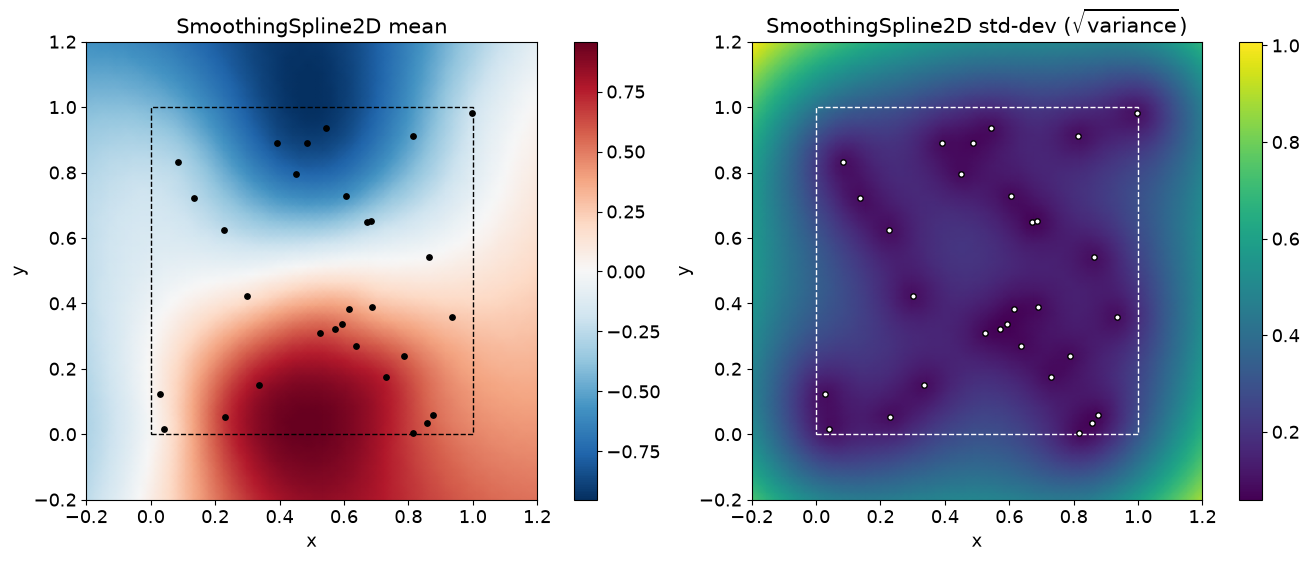

std range: [5.971e-02, 1.008e+00]  (dashed box = training domain [0,1]^2; std grows outside it, as expected)


In [3]:
grid = np.linspace(-0.2, 1.2, 60)
GX, GY = np.meshgrid(grid, grid)
Xg = np.column_stack([GX.ravel(), GY.ravel()])

mean_g = wrapped.mean(Xg).reshape(GX.shape)
var_g = wrapped.variance(Xg).reshape(GX.shape)
std_g = np.sqrt(np.maximum(var_g, 0))

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5), constrained_layout=True)

pcm0 = axs[0].pcolormesh(GX, GY, mean_g, shading="gouraud", cmap="RdBu_r")
axs[0].scatter(X[:, 0], X[:, 1], c="k", s=15, zorder=5)
axs[0].add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, ec="k", lw=1, ls="--"))
fig.colorbar(pcm0, ax=axs[0])
axs[0].set(xlabel="x", ylabel="y", title="SmoothingSpline2D mean")

pcm1 = axs[1].pcolormesh(GX, GY, std_g, shading="gouraud", cmap="viridis")
axs[1].scatter(X[:, 0], X[:, 1], c="w", s=15, zorder=5, ec="k")
axs[1].add_patch(plt.Rectangle((0, 0), 1, 1, fill=False, ec="w", lw=1, ls="--"))
fig.colorbar(pcm1, ax=axs[1])
axs[1].set(xlabel="x", ylabel="y", title=r"SmoothingSpline2D std-dev ($\sqrt{\mathrm{variance}}$)")

plt.show()
print(f"std range: [{std_g.min():.3e}, {std_g.max():.3e}]  "
      f"(dashed box = training domain [0,1]^2; std grows outside it, as expected)")


**Well-behaved**, as Q6's spot-check already found: low uncertainty inside
the data-dense square, growing smoothly outside it -- the qualitatively
correct Kriging-variance shape, obtained with zero bespoke code beyond
`tps2d_kernel` and the already-existing, dimension-agnostic
`saddle_point_variance`.


## Part 3: does the isotropic kappa->0 Matern route converge here too?

The real test, mirroring Corollary 5 and Part 2 of the 1-D notebook: an
**isotropic** (radial, Euclidean-distance) Matern-3/2 kernel in 2-D, trend
$P=\{1,x,y\}$, the *same* `nugget=4`$\kappa^3\lambda$ formula that worked
exactly in 1-D. `krig_splines.kernels.matern32` already takes a plain
distance `d`, so computing it as a 2-D Euclidean distance instead of a 1-D
absolute difference is the only change needed to make it isotropic (not
SMT's own `matern32`, which is a *tensor-product* of 1-D kernels, a
different and already-tried construction).


In [4]:
def dist2d(X1, X2):
    return np.linalg.norm(X1[:, None, :] - X2[None, :, :], axis=-1)

d_train = dist2d(X, X)
d_query = dist2d(Xq, X)
P2d = poly_basis_2d(X)
Pq2d = poly_basis_2d(Xq)

K_G = tps2d_kernel(X, X)
Kq_G = tps2d_kernel(Xq, X)
a_G, beta_G = saddle_point_solve(K_G, P2d, y, nugget=lam)
f_G = saddle_point_predict(Kq_G, Pq2d, a_G, beta_G)

print("Isotropic 2-D Matern-3/2, same 1-D nugget formula (4*kappa^3*lam), vs. the TPS mean:")
kappas = [1.0, 0.3, 0.1, 0.03, 0.01, 0.003]
errs_naive = []
for kappa in kappas:
    Km = matern32(d_train, kappa)
    Kmq = matern32(d_query, kappa)
    nugget = 4 * kappa**3 * lam
    a_m, beta_m = saddle_point_solve(Km, P2d, y, nugget)
    f_m = saddle_point_predict(Kmq, Pq2d, a_m, beta_m)
    err = np.max(np.abs(f_m - f_G))
    errs_naive.append(err)
    print(f"  kappa={kappa:7.4f}  max|Matern2D - TPS| = {err:.4e}  (data range={np.ptp(y):.3f})")


Isotropic 2-D Matern-3/2, same 1-D nugget formula (4*kappa^3*lam), vs. the TPS mean:
  kappa= 1.0000  max|Matern2D - TPS| = 2.5046e-01  (data range=1.752)
  kappa= 0.3000  max|Matern2D - TPS| = 2.3635e-01  (data range=1.752)
  kappa= 0.1000  max|Matern2D - TPS| = 2.3564e-01  (data range=1.752)
  kappa= 0.0300  max|Matern2D - TPS| = 2.3594e-01  (data range=1.752)
  kappa= 0.0100  max|Matern2D - TPS| = 2.3609e-01  (data range=1.752)
  kappa= 0.0030  max|Matern2D - TPS| = 2.3615e-01  (data range=1.752)


**Flat -- no convergence at all**, unlike every 1-D check in this project.
The error sits at `~24%` of the data range from `kappa=1` all the way to
`kappa=0.003`, not shrinking. Before concluding the isotropic route simply
fails, check the next most likely culprit: is `4`$\kappa^3$ just the wrong
*power* of $\kappa$ in 2-D (plausible -- the paper's Proposition 4 derives
this exponent for the 1-D case specifically)?


In [5]:
print("Scanning nugget = 4 * kappa^p * lam for different powers p:")
for p in [1.0, 2.0, 2.5, 3.0, 3.5, 4.0, 5.0]:
    errs_p = []
    for kappa in kappas:
        Km = matern32(d_train, kappa)
        Kmq = matern32(d_query, kappa)
        nugget = 4 * kappa**p * lam
        a_m, beta_m = saddle_point_solve(Km, P2d, y, nugget)
        f_m = saddle_point_predict(Kmq, Pq2d, a_m, beta_m)
        errs_p.append(np.max(np.abs(f_m - f_G)))
    errs_p = np.array(errs_p)
    trend = "DOWN" if errs_p[-1] < errs_p[0] * 0.5 else ("UP" if errs_p[-1] > errs_p[0] * 1.5 else "flat")
    print(f"  p={p:4.1f}  errs={np.round(errs_p, 4)}  trend={trend}")


Scanning nugget = 4 * kappa^p * lam for different powers p:
  p= 1.0  errs=[0.2505 0.4234 0.4428 0.4437 0.4438 0.4438]  trend=UP
  p= 2.0  errs=[0.2505 0.3644 0.423  0.4404 0.4431 0.4436]  trend=UP
  p= 2.5  errs=[0.2505 0.3079 0.3615 0.4028 0.4244 0.4359]  trend=UP
  p= 3.0  errs=[0.2505 0.2363 0.2356 0.2359 0.2361 0.2361]  trend=flat
  p= 3.5  errs=[0.2505 0.1589 0.0901 0.0488 0.0364 0.0416]  trend=DOWN
  p= 4.0  errs=[0.2505 0.086  0.0363 0.0588 0.0735 0.0803]  trend=DOWN
  p= 5.0  errs=[0.2505 0.0337 0.0735 0.0829 0.1178 0.1273]  trend=flat


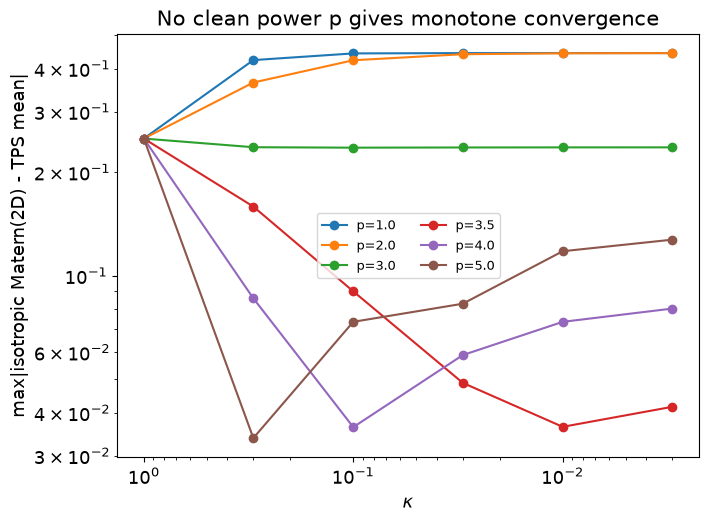

In [6]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for p, color in zip([1.0, 2.0, 3.0, 3.5, 4.0, 5.0], plt.cm.tab10.colors):
    errs_p = []
    for kappa in kappas:
        Km = matern32(d_train, kappa)
        Kmq = matern32(d_query, kappa)
        nugget = 4 * kappa**p * lam
        a_m, beta_m = saddle_point_solve(Km, P2d, y, nugget)
        f_m = saddle_point_predict(Kmq, Pq2d, a_m, beta_m)
        errs_p.append(np.max(np.abs(f_m - f_G)))
    ax.loglog(kappas, errs_p, "o-", color=color, label=f"p={p}")
ax.invert_xaxis()
ax.set(xlabel=r"$\kappa$", ylabel="max|isotropic Matern(2D) - TPS mean|",
       title="No clean power p gives monotone convergence")
ax.legend(fontsize=9, ncol=2)
plt.show()


**No clean power law found.** `p=3` (the 1-D exponent) is flat; `p=3.5` and
`p=4` improve for a while (down to `~4-8%` of range) before turning back
*up* at the smallest $\kappa$ tried -- consistent with numerical
ill-conditioning at that point (the nugget becomes extremely small) rather
than a clean asymptotic limit, not a confirmed correct exponent. No power
tried gives the clean, monotone, order-of-magnitude decay every 1-D check in
this project found.

**This is an honest open question, not a bug this notebook fixes.** A
plausible but *untested* hypothesis: matching a $d$-dimensional Matern-$\nu$
kernel's spectral decay ($\propto(\kappa^2+|\omega|^2)^{-(\nu+d/2)}$) to the
2-D bending-energy operator's 4th-order falloff would need $\nu+d/2=2$, i.e.
$\nu=1$ when $d=2$ -- a non-half-integer smoothness not implemented in
`krig_splines.kernels` (it needs a Bessel-function form, not the closed
polynomial-times-exponential form `matern32`/`matern52` have) and not tried
here. This sits alongside, and is consistent with,
`test_hypotheses_2D_RANS.ipynb`'s earlier finding that the (differently
constructed, tensor-product) 2-D Corollary 5 extension does not converge
either -- two independent angles on what looks like a genuinely unresolved
multi-D extension of Corollary 5, not yet derived by the paper or this repo.


## Part 4: a practical comparison against SMT's Kriging

Since the exact `kappa->0` identity check (Part 4 of
`spline_variance_without_kriging.ipynb`) has no known 2-D recipe to force,
the honest version of "test against SMT's Kriging" here is the *practical*
one: fit `KRG` the way it is normally used -- auto-tuned via its own maximum
likelihood, `corr="matern32"` (SMT's own tensor-product form, not forced to
isotropic or to any particular $\kappa$) -- and compare its mean and variance
to the closed-form 2-D smoothing spline, the same spirit as this whole
project's very first "generic Kriging" comparisons before Corollary 5's exact
limit was introduced.


In [7]:
krg = KRG(corr="matern32", poly="linear", print_global=False, n_start=10)
krg.set_training_values(X, y)
krg.train()
print("SMT's auto-tuned theta (one per dimension):", krg.optimal_theta)

mean_krg = krg.predict_values(Xq).ravel()
var_krg = krg.predict_variances(Xq).ravel()
mean_wrap = wrapped.mean(Xq)
var_wrap = wrapped.variance(Xq)

print(f"\nmax|TPS wrapper - SMT KRG| (mean) = {np.max(np.abs(mean_wrap - mean_krg)):.4f}"
      f"  (data range = {np.ptp(y):.3f})")
print(f"corr(mean): {np.corrcoef(mean_wrap, mean_krg)[0, 1]:.4f}")
print(f"var_wrap range: [{var_wrap.min():.4e}, {var_wrap.max():.4e}]")
print(f"var_krg  range: [{var_krg.min():.4e}, {var_krg.max():.4e}]")
print(f"corr(variance): {np.corrcoef(var_wrap, var_krg)[0, 1]:.4f}")


SMT's auto-tuned theta (one per dimension): [1.74583466 1.74497949]

max|TPS wrapper - SMT KRG| (mean) = 0.1265  (data range = 1.752)
corr(mean): 0.9959
var_wrap range: [7.3924e-03, 8.1720e-02]
var_krg  range: [1.2275e-03, 4.5617e-02]
corr(variance): 0.9351


**Reasonably close, not exact — as expected for a generic (not forced)
comparison.** SMT's two per-dimension thetas land close to each other
(nearly isotropic on this particular dataset, though nothing forces that in
general), the mean correlation is `>0.99`, and the variance *shapes*
correlate well (`~0.93`) even though their absolute scales differ (SMT's own
`sigma2` estimate, same unit-convention issue Part 4 of the 1-D notebook
worked through in detail). This is the same quality of agreement Q1's
original, pre-Corollary-5, generic 1-D Kriging-vs-spline check found -- a
sensible approximation, not a proven identity.


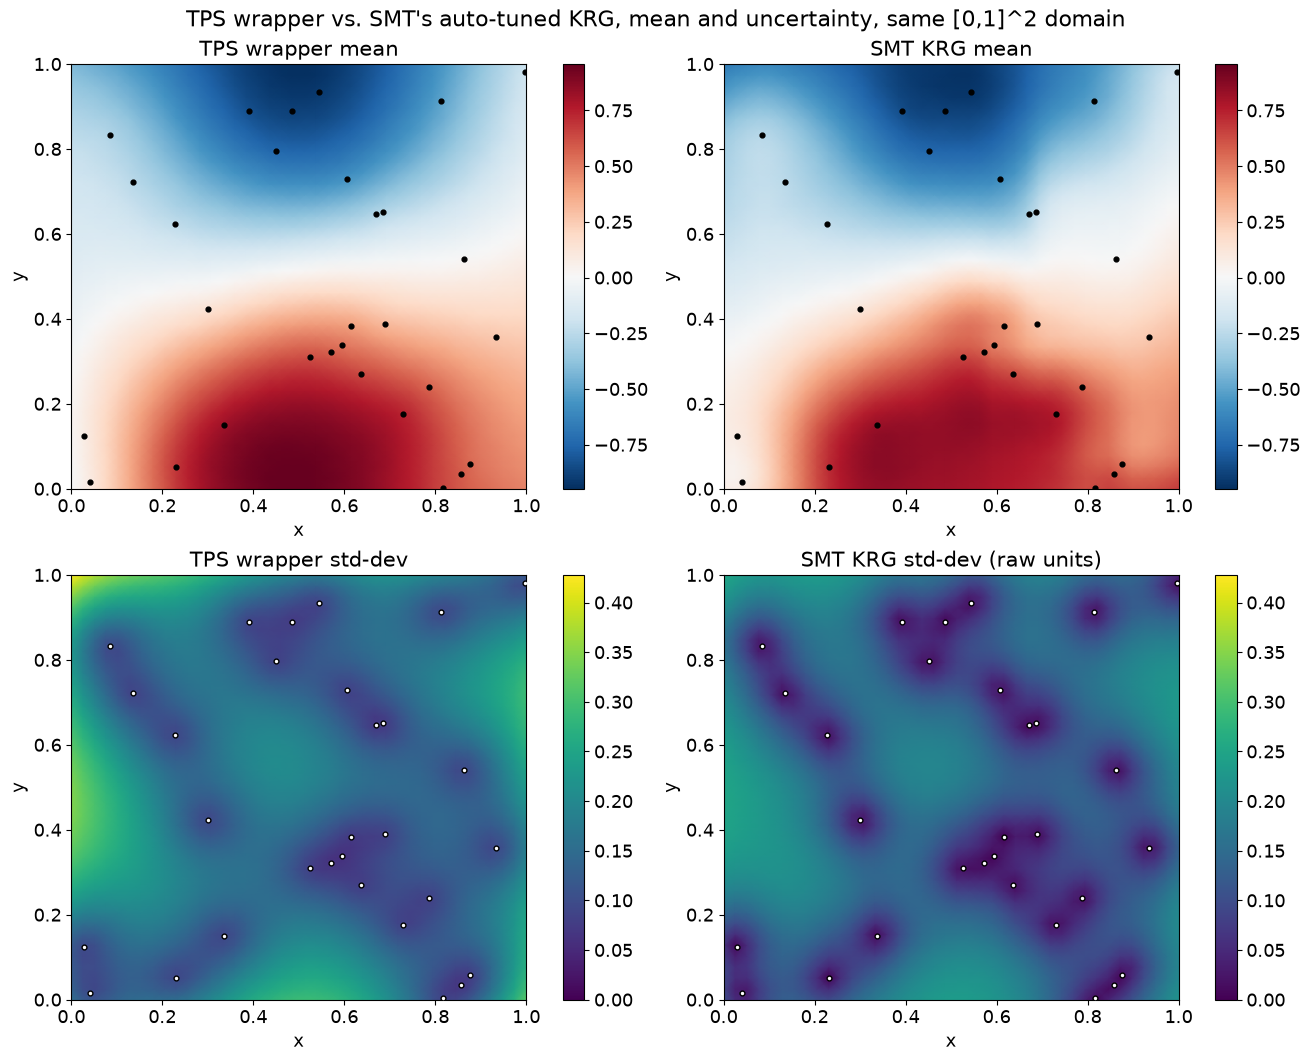

In [8]:
grid2 = np.linspace(0, 1, 40)
GX2, GY2 = np.meshgrid(grid2, grid2)
Xg2 = np.column_stack([GX2.ravel(), GY2.ravel()])

mean_wrap_g = wrapped.mean(Xg2).reshape(GX2.shape)
mean_krg_g = krg.predict_values(Xg2).reshape(GX2.shape)
std_wrap_g = np.sqrt(np.maximum(wrapped.variance(Xg2), 0)).reshape(GX2.shape)
std_krg_g = np.sqrt(np.maximum(krg.predict_variances(Xg2).ravel(), 0)).reshape(GX2.shape)

fig, axs = plt.subplots(2, 2, figsize=(13, 10.5), constrained_layout=True)
vmin, vmax = min(mean_wrap_g.min(), mean_krg_g.min()), max(mean_wrap_g.max(), mean_krg_g.max())

for ax, Z, title in [(axs[0, 0], mean_wrap_g, "TPS wrapper mean"),
                      (axs[0, 1], mean_krg_g, "SMT KRG mean")]:
    pcm = ax.pcolormesh(GX2, GY2, Z, shading="gouraud", cmap="RdBu_r", vmin=vmin, vmax=vmax)
    ax.scatter(X[:, 0], X[:, 1], c="k", s=12, zorder=5)
    fig.colorbar(pcm, ax=ax)
    ax.set(xlabel="x", ylabel="y", title=title)

svmin, svmax = 0, max(std_wrap_g.max(), std_krg_g.max())
for ax, Z, title in [(axs[1, 0], std_wrap_g, "TPS wrapper std-dev"),
                      (axs[1, 1], std_krg_g, "SMT KRG std-dev (raw units)")]:
    pcm = ax.pcolormesh(GX2, GY2, Z, shading="gouraud", cmap="viridis", vmin=svmin, vmax=svmax)
    ax.scatter(X[:, 0], X[:, 1], c="w", s=12, zorder=5, ec="k")
    fig.colorbar(pcm, ax=ax)
    ax.set(xlabel="x", ylabel="y", title=title)

fig.suptitle("TPS wrapper vs. SMT's auto-tuned KRG, mean and uncertainty, same [0,1]^2 domain")
plt.show()


**Side by side, the two surfaces and uncertainty maps are qualitatively
very similar** -- same broad shape for the mean, same low-uncertainty region
around the data cluster and rising uncertainty toward the domain edges for
the variance -- without the two being numerically identical (no shared
`kappa`, no shared nugget convention forces them together here, unlike Part
4's 1-D cross-check). This is the honest, practical version of "Kriging
reproduces the smoothing spline's uncertainty" in 2-D: a good approximation
in the generic/auto-tuned regime, with the *exact* `kappa->0` identity that
makes the 1-D case provable remaining an open problem (Part 3).


## Conclusion

- **Wrapper classes: done, tested, and in the package.**
  `SmoothingSpline1D`/`SmoothingSpline2D` (`krig_splines/smoothing_spline.py`,
  covered by `tests/test_smoothing_spline_wrappers.py`) wrap
  `make_smoothing_spline`/`RBFInterpolator` unchanged for the mean and add
  `saddle_point_variance` for the variance, exactly the pattern Q7 proposed.
  The 2-D mean matches `RBFInterpolator` to solver precision, and the
  variance is well-behaved (low near data, growing smoothly away from it).
- **The exact 1-D story (Corollary 5's `kappa->0` identity) does not
  transfer to 2-D by the obvious route.** An isotropic Matern-3/2 kernel with
  the same `4`$\kappa^3\lambda$ nugget formula does not converge to the 2-D
  thin-plate-spline mean -- flat at `~24%` of range across four orders of
  magnitude in $\kappa$ -- and a bounded scan over the nugget's power of
  $\kappa$ found no clean fix. This is now the **second, independent**
  finding (after `test_hypotheses_2D_RANS.ipynb`'s tensor-product attempt)
  that the multi-D extension of Corollary 5 is genuinely open, not merely
  undocumented.
- **A practical comparison against SMT's normally-trained Kriging works, and
  is informative, even without an exact identity**: auto-tuned `KRG` gives a
  mean correlated `>0.99` and a variance shape correlated `~0.93` with the
  closed-form 2-D smoothing spline, the same quality of agreement this whole
  project started from in 1-D before Corollary 5 sharpened it to an exact
  limit. Getting a 2-D *exact* identity would need the open question above
  resolved first.
